# 4. SciPy allocation and native code

Start by describing measurements and minimising simple functions.
Then use the same solver interface to choose portfolio weights.
The notebook uses NumPy if the native libraries have not been built.

In [1]:
from __future__ import annotations

from collections.abc import Callable
from functools import partial
from statistics import median
from timeit import repeat

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Code, display
from scipy import stats
from scipy.optimize import minimize, minimize_scalar

from quant_workshop.market import ASSETS, TRADING_DAYS, FloatArray, synthetic_prices
from quant_workshop.native import LIBRARY_SUFFIX, NATIVE_DIR, load_downside

## SciPy statistics

NumPy supplies arrays; SciPy adds statistical models, numerical solvers and other algorithms.
For a few invented height measurements, `describe` reports a count, range, mean and sample variance.
Variance is the square of standard deviation.

In [2]:
heights: FloatArray = np.array([160.0, 165.0, 170.0, 175.0, 180.0])
height_summary = stats.describe(heights)
print("Count:", height_summary.nobs)
print("Range:", height_summary.minmax)
print("Mean:", height_summary.mean, "Sample variance:", height_summary.variance)
np.testing.assert_allclose(height_summary.mean, 170.0)

Count: 5
Range: (np.float64(160.0), np.float64(180.0))
Mean: 170.0 Sample variance: 62.5


A normal-distribution model has a centre (`loc`) and a standard deviation (`scale`).
`.cdf(value)` gives the fraction of the model below a value.
`.ppf(fraction)` does the reverse: it finds the value below which that fraction lies.

In [3]:
height_model = stats.norm(loc=170.0, scale=10.0)
print(f"Model fraction below 180 cm: {height_model.cdf(180.0):.1%}")
print(f"Model 95th percentile: {height_model.ppf(0.95):.1f} cm")
np.testing.assert_allclose(height_model.cdf(170.0), 0.5)
np.testing.assert_allclose(height_model.cdf(height_model.ppf(0.95)), 0.95)

Model fraction below 180 cm: 84.1%
Model 95th percentile: 186.4 cm


## Minimising one number

A solver tries inputs to find a small function value. The function is the **objective**.
For `(x - 3)² + 2`, the answer is x = 3, where the squared term is zero.
`minimize_scalar` takes the function itself, not the result of calling it once.

In [4]:
def bowl(x: float) -> float:
    return (x - 3.0) ** 2 + 2.0


scalar_fit = minimize_scalar(bowl, bounds=(0.0, 6.0), method="bounded")
if not scalar_fit.success:
    raise RuntimeError(f"Scalar optimisation failed: {scalar_fit.message}")
print("Best input:", scalar_fit.x, "Function value:", scalar_fit.fun)
np.testing.assert_allclose(scalar_fit.x, 3.0, atol=1e-6)
np.testing.assert_allclose(scalar_fit.fun, 2.0, atol=1e-10)

Best input: 3.0 Function value: 2.0


## Several numbers, bounds and a constraint

Mix red and blue paint. The target is 20% red and 80% blue.
The objective sums squared differences from those target proportions.
`minimize` accepts an array of inputs, a starting guess and bounds for each input.
An equality constraint is a function that must return zero: here `sum(proportions) - 1`.

In [5]:
target_mix: FloatArray = np.array([0.2, 0.8])


def colour_error(proportions: FloatArray) -> float:
    return float(np.sum((proportions - target_mix) ** 2))


def unit_sum(proportions: FloatArray) -> float:
    return float(proportions.sum() - 1.0)


colour_fit = minimize(
    colour_error,
    x0=np.array([0.5, 0.5]),
    method="SLSQP",
    bounds=[(0.0, 1.0), (0.0, 1.0)],
    constraints={"type": "eq", "fun": unit_sum},
    options={"ftol": 1e-12},
)
if not colour_fit.success:
    raise RuntimeError(f"Colour optimisation failed: {colour_fit.message}")
print("Red and blue proportions:", colour_fit.x.round(3))
np.testing.assert_allclose(colour_fit.x, target_mix, atol=1e-6)
np.testing.assert_allclose(colour_fit.x.sum(), 1.0, atol=1e-8)

Red and blue proportions: [0.2 0.8]


**Exercise:** change the target to 40% red and 60% blue. Predict the result before rerunning
the cell, then restore the original target. The solver repeatedly calls our functions with
trial arrays; we do not need to write that search loop ourselves.

## Using the solver for a portfolio

Replace paint proportions with fractions invested in assets. The function to minimise will now
measure estimated portfolio variance. The starting guess, bounds, constraint and success checks
use the same interface as the colour example.

A portfolio **weight** is the fraction invested in an asset. Weights sum to 1.
Covariance measures how returns move together; its diagonal contains their variances.
As in the quiz example in notebook 2, `np.cov(..., rowvar=False)` treats columns as variables.
We multiply daily covariance by 252 to annualise it, assuming uncorrelated, stable daily returns.

In [6]:
prices: pd.DataFrame = synthetic_prices()
daily_returns: pd.DataFrame = prices.pct_change(fill_method=None).dropna()
training_rows: int = 503
training: FloatArray = daily_returns.iloc[:training_rows].to_numpy(dtype=np.float64)
evaluation: FloatArray = daily_returns.iloc[training_rows:].to_numpy(dtype=np.float64)
covariance: FloatArray = np.cov(training, rowvar=False, ddof=1) * TRADING_DAYS
equal_weights: FloatArray = np.full(len(ASSETS), 1.0 / len(ASSETS))
print(f"Training returns: {training.shape}; evaluation returns: {evaluation.shape}")
print("Annualised sample covariance:\n", covariance.round(4))

Training returns: (503, 3); evaluation returns: (252, 3)
Annualised sample covariance:
 [[0.0185 0.0157 0.0067]
 [0.0157 0.0464 0.0162]
 [0.0067 0.0162 0.0894]]


For weights `w`, portfolio variance is `w @ covariance @ w`; `@` is matrix multiplication.

We minimise estimated variance, with no short selling and no borrowing.
The estimate uses the first 503 daily returns, corresponding to the first 504 prices.
The last 252 returns are evaluated afterwards, matching notebook 3's split.
Lower estimated training-period risk does not guarantee lower evaluation-period risk.

In [7]:
def portfolio_variance(weights: FloatArray) -> float:
    return float(weights @ covariance @ weights)


def fully_invested(weights: FloatArray) -> float:
    return float(weights.sum() - 1.0)


optimisation = minimize(
    portfolio_variance,
    x0=equal_weights,
    method="SLSQP",
    bounds=[(0.0, 1.0)] * len(ASSETS),
    constraints={"type": "eq", "fun": fully_invested},
    options={"ftol": 1e-12, "maxiter": 200},
)
if not optimisation.success:
    raise RuntimeError(f"Allocation failed: {optimisation.message}")

weights: FloatArray = np.asarray(optimisation.x, dtype=np.float64)
assert np.isfinite(weights).all()
assert (weights >= -1e-8).all() and (weights <= 1.0 + 1e-8).all()
np.testing.assert_allclose(weights.sum(), 1.0, atol=1e-8)
assert portfolio_variance(weights) <= portfolio_variance(equal_weights) + 1e-10
print(pd.Series(weights, index=list(ASSETS), name="Weight").round(3).to_string())

ALPHA    0.842
BETA     0.038
GAMMA    0.119


SciPy supplies the numerical algorithm; we supply the objective, bounds, and constraints.
SLSQP is a solver for constrained optimisation. Check its success flag and the weight constraints.

`evaluation @ weights` computes one portfolio return per date, using the same weights each day.
That models **daily rebalancing to fixed weights**, rather than buying once and letting weights drift.
This allocation example excludes rebalancing costs.

Evaluation statistics (fractions):
       Allocation  Total return  Annualised volatility
    Equal weight        0.3515                 0.1651
Minimum variance        0.3011                 0.1376


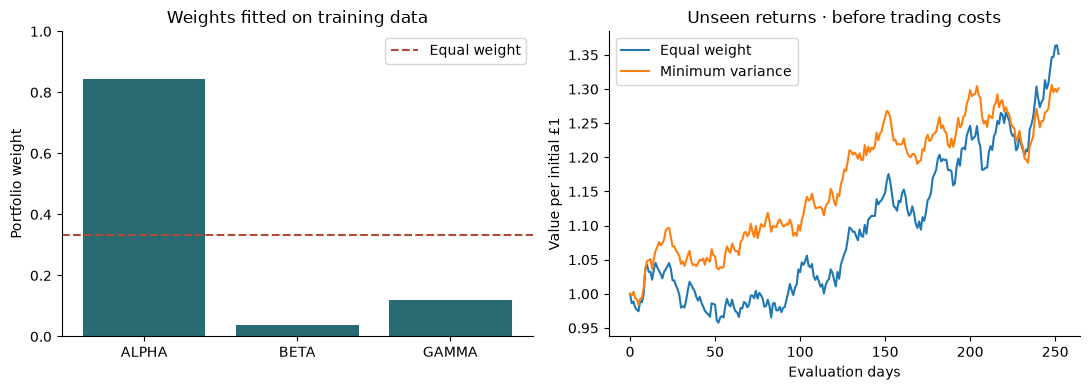

In [8]:
evaluation_returns: dict[str, FloatArray] = {
    "Equal weight": evaluation @ equal_weights,
    "Minimum variance": evaluation @ weights,
}
rows: list[dict[str, str | float]] = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(list(ASSETS), weights, color="#286b73")
axes[0].axhline(1.0 / len(ASSETS), linestyle="--", color="#b34a36", label="Equal weight")
axes[0].set(ylabel="Portfolio weight", title="Weights fitted on training data", ylim=(0.0, 1.0))
axes[0].legend()
for label, values in evaluation_returns.items():
    equity: FloatArray = np.concatenate([np.array([1.0]), np.cumprod(1.0 + values)])
    rows.append(
        {
            "Allocation": label,
            "Total return": float(equity[-1] - 1.0),
            "Annualised volatility": float(values.std(ddof=1) * np.sqrt(TRADING_DAYS)),
        }
    )
    axes[1].plot(equity, label=label)
axes[1].set(
    xlabel="Evaluation days",
    ylabel="Value per initial £1",
    title="Unseen returns · before trading costs",
)
axes[1].legend()
plt.tight_layout()
plt.show()
print("Evaluation statistics (fractions):\n", pd.DataFrame(rows).round(4).to_string(index=False))

**Optional exercise:** set a 60% maximum asset weight in the bounds and refit on the training data.
Compare the weights and evaluation-period results with the original allocation.

## Optional: calling C++ and Rust from Python

NumPy and Polars execute compiled code. A custom native function can help when profiling
identifies an expensive loop that existing libraries cannot handle efficiently.
Here C++ and Rust implement the same downside deviation calculation as NumPy,
using **all days** in the denominator.
Square the negative returns, use zero for other days, average across all days and take a square root.

In [9]:
def downside_numpy(values: FloatArray) -> float:
    if values.ndim != 1 or values.size == 0 or not np.isfinite(values).all():
        raise ValueError("Expected a non-empty, finite, one-dimensional array.")
    negative: FloatArray = np.minimum(values, 0.0)
    return float(np.sqrt(np.mean(negative**2)))


kernels: dict[str, Callable[[FloatArray], float]] = {"NumPy": downside_numpy}
for language in ("cpp", "rust"):
    library_path = NATIVE_DIR / "build" / f"downside_{language}{LIBRARY_SUFFIX}"
    if library_path.exists():
        kernels[language] = load_downside(library_path)
    else:
        print(
            f"Optional {language} library absent. From the workshop directory: uv run python native/build.py {language}"
        )

sample: FloatArray = np.array([-0.02, 0.01, -0.01, 0.0])
for label, kernel in kernels.items():
    print(f"{label}: daily downside deviation = {kernel(sample):.4%}")

NumPy: daily downside deviation = 1.1180%
cpp: daily downside deviation = 1.1180%
rust: daily downside deviation = 1.1180%


The native functions export a **C ABI**: a shared calling convention, usable from both languages.
`ctypes` is part of Python's standard library. It tells the library that the inputs are
a pointer to 64-bit floats and an unsigned length, and the result is a double.

Our typed wrapper checks shape, emptiness, and finite values, then ensures an aligned,
contiguous `float64` buffer. A suitable array is passed without copying; other layouts may copy.
The array remains alive during the synchronous call.
Incorrect pointers or function signatures can crash Python.

In [10]:
display(Code(filename=str(NATIVE_DIR / "downside.cpp"), language="cpp"))
display(Code(filename=str(NATIVE_DIR / "downside.rs"), language="rust"))
display(
    Code(
        filename=str(NATIVE_DIR.parent / "src" / "quant_workshop" / "native.py"), language="python"
    )
)

#include <cmath>
#include <cstddef>
#include <limits>

#ifdef _WIN32
#define EXPORT __declspec(dllexport)
#else
#define EXPORT
#endif

// native.py supplies a valid pointer to count finite doubles.
extern "C" EXPORT double downside_deviation(const double* values, std::size_t count) {
    if (values == nullptr || count == 0) {
        return std::numeric_limits<double>::quiet_NaN();
    }
    double total = 0.0;
    for (std::size_t i = 0; i < count; ++i) {
        if (values[i] < 0.0) {
            total += values[i] * values[i];
        }
    }
    return std::sqrt(total / static_cast<double>(count));
}

/// The caller must supply an aligned pointer to count valid, finite f64 values.
#[no_mangle]
pub unsafe extern "C" fn downside_deviation(values: *const f64, count: usize) -> f64 {
    if values.is_null() || count == 0 {
        return f64::NAN;
    }
    // SAFETY: native.py keeps the validated NumPy buffer alive during this call.
    let returns = unsafe { std::slice::from_raw_parts(values, count) };
    let mut total = 0.0;
    for &value in returns {
        if value < 0.0 {
            total += value * value;
        }
    }
    (total / count as f64).sqrt()
}

from __future__ import annotations

import ctypes
import sys
from collections.abc import Callable
from pathlib import Path

import numpy as np
from numpy.ctypeslib import ndpointer

from quant_workshop.market import FloatArray

NATIVE_DIR: Path = Path(__file__).resolve().parents[2] / "native"
LIBRARY_SUFFIX: str = (
    ".dll" if sys.platform == "win32" else (".dylib" if sys.platform == "darwin" else ".so")
)


def load_downside(library_path: Path) -> Callable[[FloatArray], float]:
    library = ctypes.CDLL(str(library_path.resolve()))
    kernel = library.downside_deviation
    kernel.argtypes = [
        ndpointer(dtype=np.float64, ndim=1, flags=("C_CONTIGUOUS", "ALIGNED")),
        ctypes.c_size_t,
    ]
    kernel.restype = ctypes.c_double

    def downside(values: FloatArray) -> float:
        if values.ndim != 1 or values.size == 0 or not np.isfinite(values).all():
            raise ValueError("Expected a non-empty, finite, one-dimensional array.")
        contiguous: FloatArray = np.require(values, dtype=np.float64, requirements=["C", "A"])
        return float(kernel(contiguous, contiguous.size))

    return downside

Before measuring speed, check ordinary returns, no losses, all losses, and a strided array.
A strided array selects every second value and is not necessarily contiguous.
Empty, non-finite, and two-dimensional inputs should be rejected by every public wrapper.

In [11]:
valid_cases: list[FloatArray] = [
    sample,
    np.array([0.0, 0.01, 0.02]),
    np.array([-0.03, -0.01, -0.02]),
    np.array([-0.02, 0.5, -0.01, 0.7])[::2],
]
invalid_cases: list[FloatArray] = [
    np.array([]),
    np.array([np.nan]),
    np.array([np.inf]),
    np.ones((2, 2)),
]
for label, kernel in kernels.items():
    for values in valid_cases:
        np.testing.assert_allclose(kernel(values), downside_numpy(values), rtol=1e-12, atol=1e-15)
    for invalid in invalid_cases:
        try:
            kernel(invalid)
        except ValueError:
            pass
        else:
            raise AssertionError(f"{label} accepted invalid returns")
print("All available kernels agree and reject invalid inputs.")

All available kernels agree and reject invalid inputs.


Inputs are prepared before timing. Each timed call includes validation and the native-call
overhead where relevant, while compilation and list conversion are excluded.
A custom native loop can fuse operations into one pass, but a small call can cost more to cross
the boundary than it saves.

In [12]:
rng = np.random.default_rng(123)
for size in (10, 1_000, 250_000):
    benchmark_values: FloatArray = rng.normal(0.0, 0.01, size)
    reference: float = downside_numpy(benchmark_values)
    print(f"\n{size:,} returns:")
    for label, kernel in kernels.items():
        np.testing.assert_allclose(kernel(benchmark_values), reference, rtol=1e-12)
        operation = partial(kernel, benchmark_values)
        operation()
        milliseconds: float = median(repeat(operation, number=3, repeat=5)) / 3.0 * 1_000.0
        print(f"  {label:>5}: {milliseconds:.4f} ms per call")


10 returns:
  NumPy: 0.0022 ms per call
    cpp: 0.0033 ms per call
   rust: 0.0028 ms per call

1,000 returns:
  NumPy: 0.0028 ms per call
    cpp: 0.0036 ms per call
   rust: 0.0049 ms per call

250,000 returns:
  NumPy: 0.1497 ms per call
    cpp: 0.3625 ms per call
   rust: 0.3005 ms per call


Further reading: [normal distribution methods](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html),
[scalar optimisation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize_scalar.html),
[constrained optimisation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html),
[Python ctypes](https://docs.python.org/3/library/ctypes.html).